In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import yfinance as yf

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# The ETFs we're analyzing
tickers = ["SPY", "QQQ"]

# Download the historical prices
data = yf.download(
    tickers,
    start="1999-01-01",
    auto_adjust=True,
    progress=False
)

# Select the closing prices for both ETFs
prices = data["Close"][tickers]

# Removed dates where either ETFs is missing data
prices = prices.dropna()

# Display first 5 rows
print(prices.head())

Ticker            SPY        QQQ
Date                            
1999-03-10  79.890343  42.982273
1999-03-11  80.779274  43.192711
1999-03-12  80.006294  42.140514
1999-03-15  81.146454  43.350544
1999-03-16  80.837288  43.718807


In [3]:
# Download historical VIX data
vix_data = yf.download(
    "^VIX",
    start="1999-01-01",
    auto_adjust=True,
    progress=False
)

# Extract closing values
vix = vix_data["Close"].squeeze().dropna()

print("First VIX observation:", vix.index.min())
print("Last VIX observation:", vix.index.max())
print(vix.head())

First VIX observation: 1999-01-04 00:00:00
Last VIX observation: 2026-11-04 00:00:00
Date
1999-01-04    26.170000
1999-01-05    24.459999
1999-01-06    23.340000
1999-01-07    24.370001
1999-01-08    23.280001
Name: ^VIX, dtype: float64


In [4]:
print("Total trading days:", len(prices))
print("First trading day", prices.index.min())
print("Last trading day:", prices.index.max())

print("\nMissing values:")
print(prices.isna().sum())

print("\nData types:")
print(prices.dtypes)

Total trading days: 6958
First trading day 1999-03-10 00:00:00
Last trading day: 2026-11-04 00:00:00

Missing values:
Ticker
SPY    0
QQQ    0
dtype: int64

Data types:
Ticker
SPY    float64
QQQ    float64
dtype: object


In [5]:
# Calculates the daily precentage return
daily_returns = prices.pct_change().dropna()

print(daily_returns.head())

Ticker           SPY       QQQ
Date                          
1999-03-11  0.011127  0.004896
1999-03-12 -0.009569 -0.024361
1999-03-15  0.014251  0.028714
1999-03-16 -0.003810  0.008495
1999-03-17 -0.004304 -0.007220


In [6]:
# portfolio allocation 60/40

spy_weight = 0.60
qqq_weight = 0.40

# Calculates daily portfolio returns 
portfolio_returns = (
    spy_weight * daily_returns["SPY"] + qqq_weight * daily_returns["QQQ"]
)

print(portfolio_returns.head())

Date
1999-03-11    0.008635
1999-03-12   -0.015486
1999-03-15    0.020036
1999-03-16    0.001112
1999-03-17   -0.005470
dtype: float64


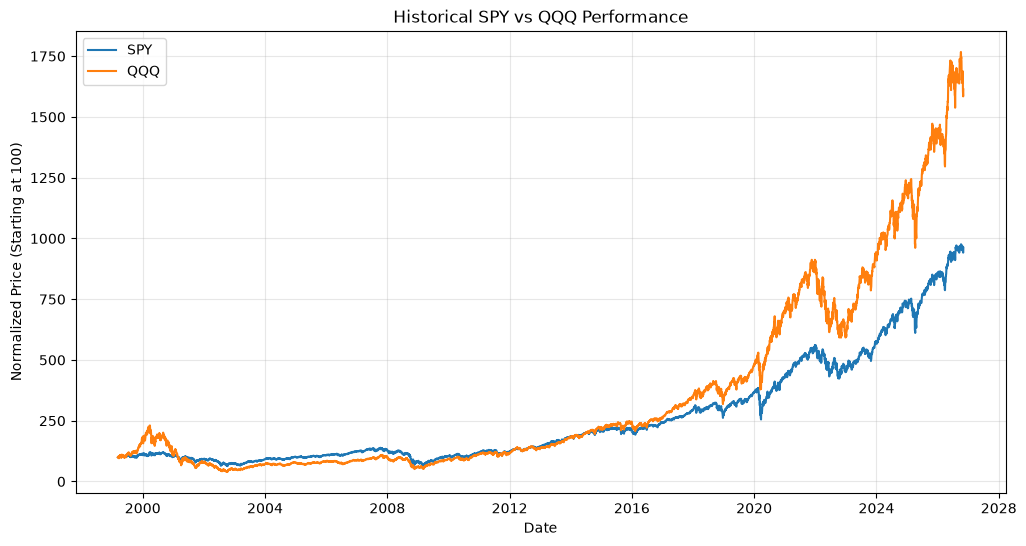

In [7]:
# Normalize both ETFs to start at 100
normalized = prices.div(prices.iloc[0]).mul(100)

plt.figure(figsize=(12,6))

plt.plot(normalized.index, normalized["SPY"], label="SPY")
plt.plot(normalized.index, normalized["QQQ"], label="QQQ")

plt.title("Historical SPY vs QQQ Performance")
plt.xlabel("Date")
plt.ylabel("Normalized Price (Starting at 100)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [8]:
# Convert daily portfolio returns to monthly returns
monthly_returns = (
    (1 + portfolio_returns).resample("ME").prod() - 1
)

print(monthly_returns.head())
print("Total months:", len(monthly_returns))

Date
1999-03-31    0.008841
1999-04-30    0.032985
1999-05-31   -0.025754
1999-06-30    0.076641
1999-07-31   -0.025588
Freq: ME, dtype: float64
Total months: 333


In [9]:
def compare_strategies(
    returns,
    initial_investment=50000,
    investment_months=12
):
    # Strategy A: invest all money immediately
    lump_sum = initial_investment 

    # Strategy B: invest gradually 
    monthly_portfolio = 0.0
    cash = initial_investment

    #Equal installments over 12 months
    contribution = initial_investment / investment_months

    lump_history = []
    monthly_history = []

    for month, monthly_return in enumerate(returns):

        #strategy A grows with the market
        lump_sum *= (1 + monthly_return)

        #strategy B invests during first 12 months 
        if month < investment_months:
            monthly_portfolio += contribution 
            cash -= contribution
        
        # Invested money grows with the market
        monthly_portfolio *= (1 + monthly_return)

        # Record total wealth, including cash
        lump_history.append(lump_sum)
        monthly_history.append(monthly_portfolio + cash)
    
    return pd.DataFrame({
        "Lump Sum": lump_history,
        "Monthly Investing": monthly_history
    }, index=returns.index)

In [10]:
assert len(monthly_returns) >= 121, \
    "Not enough monthly observations for a 10-year test"
    
# Select the first 120 complete months
test_returns = monthly_returns.iloc[1:121]

# Run both strats
test_results = compare_strategies(test_returns)

print(test_results.head())

# Final portfolio values
print("\nFinal values:")
print(test_results.iloc[-1])

# Difference between strats
difference = (
    test_results["Lump Sum"].iloc[-1] - test_results["Monthly Investing"].iloc[-1]
)

print(f"Difference: ${difference:,.2f}")

                Lump Sum  Monthly Investing
Date                                       
1999-04-30  51649.232012       50137.436001
1999-05-31  50319.071697       49919.282105
1999-06-30  54175.587393       50871.111198
1999-07-31  52789.328342       50422.349966
1999-08-31  53768.888664       50816.771048

Final values:
Lump Sum             35571.674578
Monthly Investing    31439.035664
Name: 2009-03-31 00:00:00, dtype: float64
Difference: $4,132.64


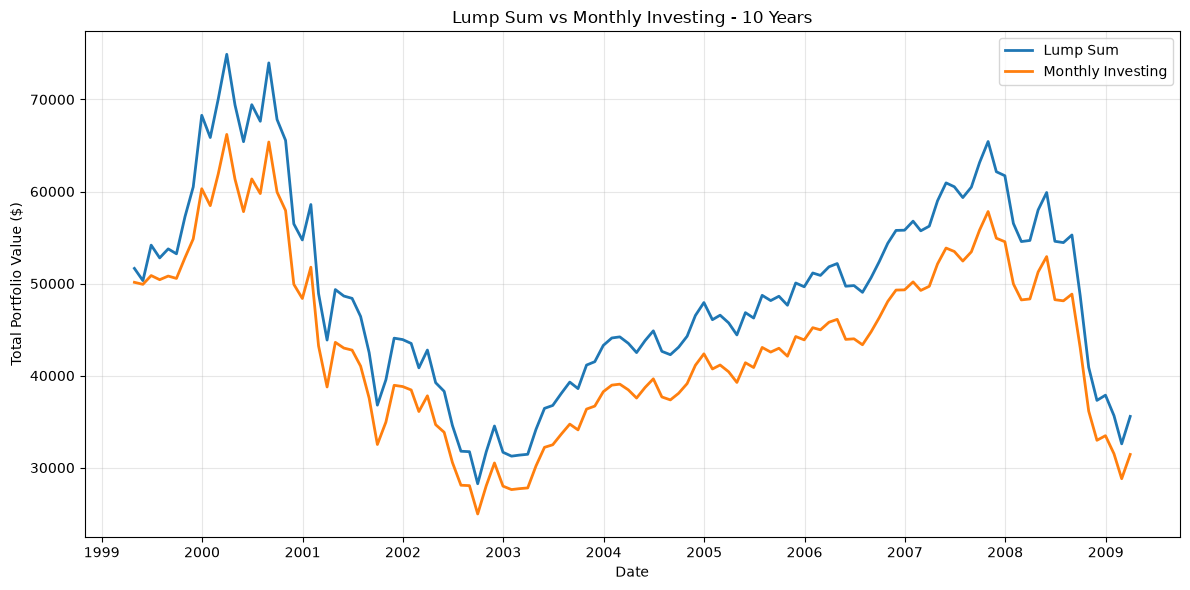

In [11]:
plt.figure(figsize=(12, 6))

plt.plot(
    test_results.index,
    test_results["Lump Sum"],
    label="Lump Sum",
    linewidth=2
)

plt.plot(
    test_results.index,
    test_results["Monthly Investing"],
    label="Monthly Investing",
    linewidth=2
)

plt.title("Lump Sum vs Monthly Investing - 10 Years")
plt.xlabel("Date")
plt.ylabel("Total Portfolio Value ($)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [12]:
#verification

# Both startegies should produce 120 monthly values
assert len(test_results) == 120

# No portfolio values should be missing
assert not test_results.isna().any().any()

# portfolio values should remain nonnegative
assert (test_results >= 0).all().all()

print("A/B strategy checks passed!")

A/B strategy checks passed!


In [13]:

def historical_backtest(monthly_returns, years=10):
    months = years * 12
    results = []

    # Loop through every eligible starting month
    for start in range(len(monthly_returns) - months + 1):

        # Select a complete 10-year period
        window = monthly_returns.iloc[start:start + months]

        # Run both investment strategies
        comparison = compare_strategies(window)

        # Get final portfolio values
        lump_sum_final = comparison["Lump Sum"].iloc[-1]
        monthly_final = comparison["Monthly Investing"].iloc[-1]

        # Calculate the performance difference
        difference = lump_sum_final - monthly_final

        # Save the results for this starting date
        results.append({
            "start_date": window.index[0],
            "end_date": window.index[-1],
            "lump_sum": lump_sum_final,
            "monthly": monthly_final,
            "difference": difference
        })

    return pd.DataFrame(results)


In [14]:
# Remove the first partial month
complete_monthly_returns = monthly_returns.iloc[1:].copy()

# Find the last business day of the final month
last_price_date = prices.index.max()
last_business_day = (
    last_price_date + pd.offsets.BMonthEnd(0)
)

# Remove final month only if incomplete
if last_price_date < last_business_day:
    complete_monthly_returns = (
        complete_monthly_returns.iloc[:-1]
    )

# Rerun the historical backtest
backtest_results = historical_backtest(
    complete_monthly_returns,
    years=10
)

print("Last month:", complete_monthly_returns.index[-1])
print("Total months:", len(complete_monthly_returns))
print("Historical windows:", len(backtest_results))


Last month: 2026-10-31 00:00:00
Total months: 331
Historical windows: 212


In [15]:
# Classify starting market volatility using VIX
def classify_vix(vix_value):
    if pd.isna(vix_value):
        return None
    elif vix_value < 15:
        return "Calm"
    elif vix_value > 25:
        return "Highly Volatile"
    else:
        return "Normal"


# Store the starting VIX for each historical window
backtest_results["starting_vix"] = [
    vix.asof(start_date - pd.offsets.MonthEnd(1))
    for start_date in backtest_results["start_date"]
]

backtest_results["vix_condition"] = (
    backtest_results["starting_vix"].apply(classify_vix)
)

print(
    backtest_results[
        ["start_date", "starting_vix", "vix_condition"]
    ].head(10)
)

  start_date  starting_vix    vix_condition
0 1999-04-30     23.260000           Normal
1 1999-05-31     25.070000  Highly Volatile
2 1999-06-30     25.389999  Highly Volatile
3 1999-07-31     21.090000           Normal
4 1999-08-31     24.639999           Normal
5 1999-09-30     24.450001           Normal
6 1999-10-31     25.410000  Highly Volatile
7 1999-11-30     22.200001           Normal
8 1999-12-31     24.180000           Normal
9 2000-01-31     24.639999           Normal


In [16]:
# Compare investment strategies by starting VIX condition
vix_summary = (
    backtest_results
    .dropna(subset=["starting_vix"])
    .groupby("vix_condition")
    .agg(
        periods=("difference", "count"),
        avg_difference=("difference", "mean"),
        lump_win_rate=(
            "difference",
            lambda x: (x > 0).mean() * 100
        )
    )
)

print(vix_summary.round(2))

                 periods  avg_difference  lump_win_rate
vix_condition                                          
Calm                  55         7382.82          87.27
Highly Volatile       47        11620.61          72.34
Normal               110         1863.08          63.64


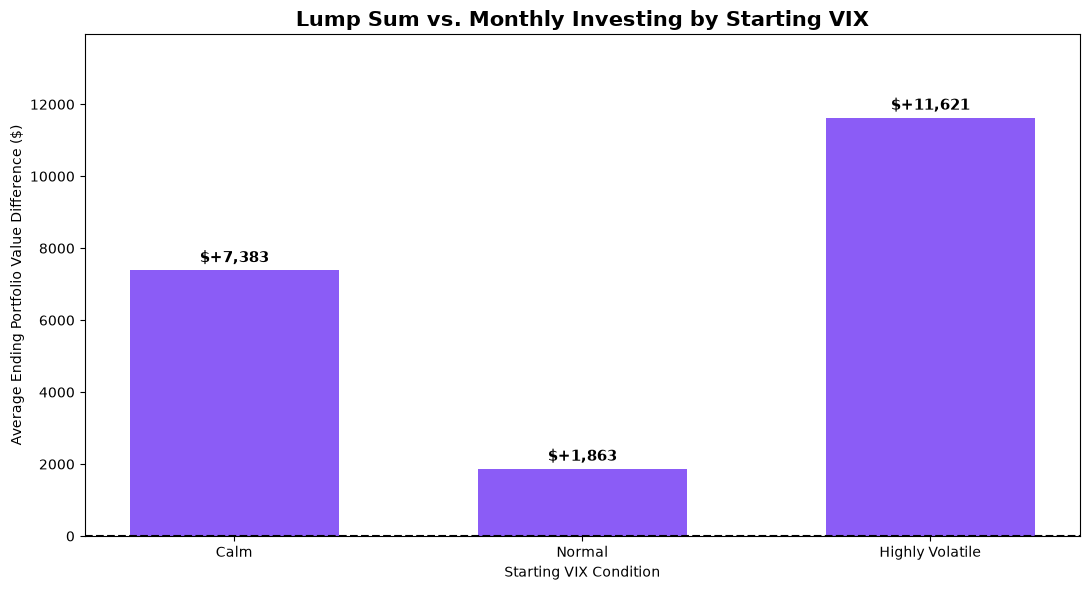

In [29]:
order = ["Calm", "Normal", "Highly Volatile"]
summary = vix_summary.loc[order]

fig, ax = plt.subplots(figsize=(11, 6))

colors = [
    "#8B5CF6" if value >= 0 else "#F472B6"
    for value in summary["avg_difference"]
]

bars = ax.bar(
    summary.index,
    summary["avg_difference"],
    color=colors,
    width=0.6
)

for bar, value in zip(bars, summary["avg_difference"]):
    ax.annotate(
        f"${value:+,.0f}",
        xy=(bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 6 if value >= 0 else -18),
        textcoords="offset points",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.axhline(0, color="black", linestyle="--")

ax.set_title(
    "Lump Sum vs. Monthly Investing by Starting VIX",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Starting VIX Condition")
ax.set_ylabel("Average Ending Portfolio Value Difference ($)")

ax.margins(y=0.2)

plt.tight_layout()
plt.show()

In [30]:
# Step 3: Test different SPY/QQQ allocations

allocations = {
    "100% SPY": (1.00, 0.00),
    "75% SPY / 25% QQQ": (0.75, 0.25),
    "50% SPY / 50% QQQ": (0.50, 0.50),
    "25% SPY / 75% QQQ": (0.25, 0.75),
    "100% QQQ": (0.00, 1.00)
}

all_results = []

for allocation_name, (spy_weight, qqq_weight) in allocations.items():

    # Calculate daily returns for this allocation
    allocation_returns = (
        spy_weight * daily_returns["SPY"]
        + qqq_weight * daily_returns["QQQ"]
    )

    # Convert daily returns to monthly returns
    allocation_monthly = (
        (1 + allocation_returns).resample("ME").prod() - 1
    )

    # Use the same complete months as the original analysis
    allocation_monthly = allocation_monthly.loc[
        complete_monthly_returns.index
    ]

    # Run historical backtesting
    allocation_backtest = historical_backtest(
        allocation_monthly,
        years=10
    )

    # Match each window with its starting VIX
    allocation_backtest = allocation_backtest.merge(
        backtest_results[
            ["start_date", "starting_vix", "vix_condition"]
        ],
        on="start_date",
        how="left",
        validate="one_to_one"
    )

    allocation_backtest["allocation"] = allocation_name

    all_results.append(allocation_backtest)

# Combine all allocation results
allocation_results = pd.concat(
    all_results,
    ignore_index=True
)

print(allocation_results.head())
print("Total comparisons:", len(allocation_results))

  start_date   end_date      lump_sum       monthly   difference  \
0 1999-04-30 2009-03-31  36613.085101  34665.176520  1947.908581   
1 1999-05-31 2009-04-30  38777.880064  37587.495658  1190.384407   
2 1999-06-30 2009-05-31  42005.026037  39471.613668  2533.412369   
3 1999-07-31 2009-06-30  39774.856968  39102.582764   672.274204   
4 1999-08-31 2009-07-31  44110.682064  41782.904875  2327.777189   

   starting_vix    vix_condition allocation  
0     23.260000           Normal   100% SPY  
1     25.070000  Highly Volatile   100% SPY  
2     25.389999  Highly Volatile   100% SPY  
3     21.090000           Normal   100% SPY  
4     24.639999           Normal   100% SPY  
Total comparisons: 1060


In [31]:
# Average final values for each allocation and VIX condition
allocation_summary = (
    allocation_results
    .dropna(subset=["starting_vix"])
    .groupby(["vix_condition", "allocation"])
    .agg(
        periods=("difference", "count"),
        avg_lump_sum=("lump_sum", "mean"),
        avg_monthly=("monthly", "mean"),
        avg_difference=("difference", "mean"),
        lump_win_rate=(
            "difference",
            lambda x: (x > 0).mean() * 100
        )
    )
    .reset_index()
)

print(allocation_summary.round(2))

      vix_condition         allocation  periods  avg_lump_sum  avg_monthly  \
0              Calm           100% QQQ       55     206301.70    194963.78   
1              Calm           100% SPY       55     133020.40    127689.52   
2              Calm  25% SPY / 75% QQQ       55     186055.63    176500.19   
3              Calm  50% SPY / 50% QQQ       55     167080.63    159114.35   
4              Calm  75% SPY / 25% QQQ       55     149400.36    142838.79   
5   Highly Volatile           100% QQQ       47     209996.32    190980.15   
6   Highly Volatile           100% SPY       47     137602.92    129871.46   
7   Highly Volatile  25% SPY / 75% QQQ       47     189793.25    174108.72   
8   Highly Volatile  50% SPY / 50% QQQ       47     171042.26    158327.50   
9   Highly Volatile  75% SPY / 25% QQQ       47     153669.94    143596.37   
10           Normal           100% QQQ      110     187079.55    184938.28   
11           Normal           100% SPY      110     126963.54   

In [32]:
# Convert both strategies into comparable rows
strategy_results = allocation_summary.melt(
    id_vars=["vix_condition", "allocation", "periods"],
    value_vars=["avg_lump_sum", "avg_monthly"],
    var_name="strategy",
    value_name="avg_final_value"
)

strategy_results["strategy"] = strategy_results["strategy"].map({
    "avg_lump_sum": "Lump Sum",
    "avg_monthly": "Monthly Investing"
})

# Find the highest average ending value per VIX condition
best_strategies = (
    strategy_results
    .sort_values("avg_final_value", ascending=False)
    .drop_duplicates("vix_condition")
    .sort_values("vix_condition")
)

print(best_strategies.to_string(index=False))

  vix_condition allocation  periods strategy  avg_final_value
           Calm   100% QQQ       55 Lump Sum    206301.697658
Highly Volatile   100% QQQ       47 Lump Sum    209996.322225
         Normal   100% QQQ      110 Lump Sum    187079.554102


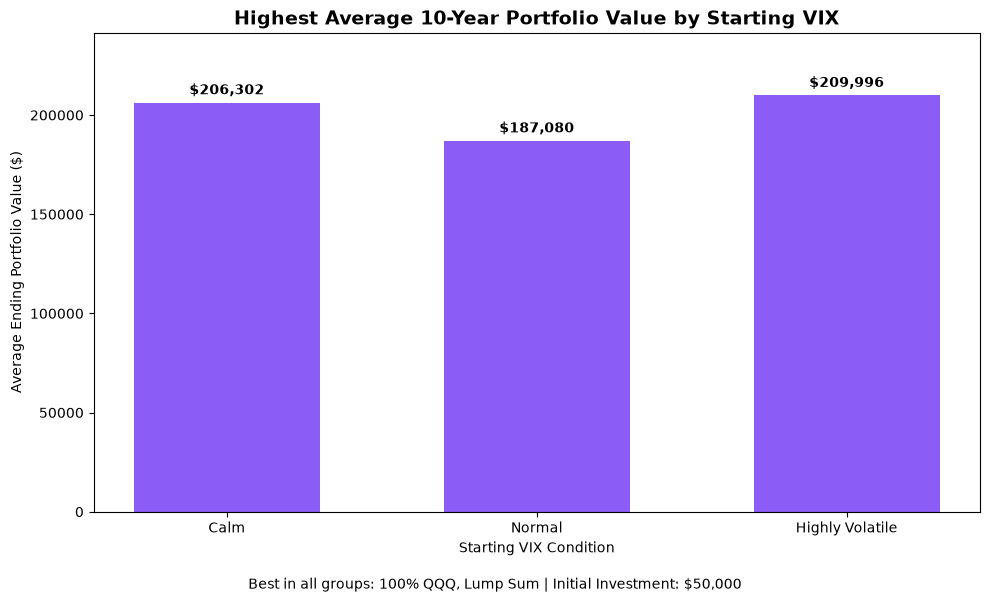

In [33]:
# Visualize best historical strategy by starting VIX
order = ["Calm", "Normal", "Highly Volatile"]

chart_data = (
    best_strategies
    .set_index("vix_condition")
    .loc[order]
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.bar(
    chart_data.index,
    chart_data["avg_final_value"],
    color="#8B5CF6",
    width=0.6
)

for bar, value in zip(bars, chart_data["avg_final_value"]):
    ax.annotate(
        f"${value:,.0f}",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            value
        ),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontweight="bold"
    )

ax.set_title(
    "Highest Average 10-Year Portfolio Value by Starting VIX",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylabel("Average Ending Portfolio Value ($)")
ax.set_xlabel("Starting VIX Condition")
ax.set_ylim(0, chart_data["avg_final_value"].max() * 1.15)

fig.text(
    0.5, 0.01,
    "Best in all groups: 100% QQQ, Lump Sum | Initial Investment: $50,000",
    ha="center",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

In [34]:
# Step 4.1: Compare the best historical allocation
# against a 100% SPY benchmark

lump_values = allocation_results.pivot(
    index="start_date",
    columns="allocation",
    values="lump_sum"
)

monthly_values = allocation_results.pivot(
    index="start_date",
    columns="allocation",
    values="monthly"
)

comparison_table = pd.DataFrame({
    "qqq_vs_spy": (
        lump_values["100% QQQ"]
        - lump_values["100% SPY"]
    ),
    "qqq_lump_vs_monthly": (
        lump_values["100% QQQ"]
        - monthly_values["100% QQQ"]
    )
})

# Attach the starting VIX classification
comparison_table = comparison_table.join(
    backtest_results.set_index("start_date")[
        ["vix_condition", "starting_vix"]
    ]
)

comparison_table = comparison_table.dropna().sort_index()

# Average historical advantages by VIX category
comparison_summary = (
    comparison_table
    .groupby("vix_condition")
    .agg(
        periods=("qqq_vs_spy", "count"),
        qqq_vs_spy=("qqq_vs_spy", "mean"),
        lump_vs_monthly=("qqq_lump_vs_monthly", "mean")
    )
)

print(comparison_summary.round(2))

                 periods  qqq_vs_spy  lump_vs_monthly
vix_condition                                        
Calm                  55    73281.30         11337.92
Highly Volatile       47    72393.40         19016.17
Normal               110    60116.02          2141.27


In [35]:
# Step 4.2: Bootstrap comparisons by starting VIX
# Resample chronological blocks of historical starting periods

def bootstrap_by_vix(
    data,
    difference_column,
    block_size=60,
    n_bootstrap=5000,
    seed=42
):
    rng = np.random.default_rng(seed)

    data = data.sort_index()
    n = len(data)

    values = data[difference_column].to_numpy()
    conditions = data["vix_condition"].to_numpy()

    categories = ["Calm", "Normal", "Highly Volatile"]

    results = []

    for category in categories:
        actual = values[conditions == category].mean()
        bootstrap_averages = []

        for _ in range(n_bootstrap):

            # Resample blocks from the complete historical timeline
            indices = []

            while len(indices) < n:
                start = rng.integers(0, n)

                block = (
                    start + np.arange(block_size)
                ) % n

                indices.extend(block.tolist())

            indices = np.array(indices[:n])

            sampled_values = values[indices]
            sampled_conditions = conditions[indices]

            matching = (
                sampled_conditions == category
            )

            if matching.any():
                bootstrap_averages.append(
                    sampled_values[matching].mean()
                )

        lower, upper = np.percentile(
            bootstrap_averages,
            [2.5, 97.5]
        )

        results.append({
            "VIX Condition": category,
            "Average Difference": actual,
            "CI Lower": lower,
            "CI Upper": upper
        })

    return pd.DataFrame(results)


# Compare QQQ and SPY
qqq_spy_bootstrap = bootstrap_by_vix(
    comparison_table,
    "qqq_vs_spy"
)

print("QQQ vs SPY:")
print(qqq_spy_bootstrap.round(2))

# Compare lump sum and monthly investing within QQQ
qqq_timing_bootstrap = bootstrap_by_vix(
    comparison_table,
    "qqq_lump_vs_monthly"
)

print("\nQQQ Lump Sum vs Monthly Investing:")
print(qqq_timing_bootstrap.round(2))

QQQ vs SPY:
     VIX Condition  Average Difference  CI Lower   CI Upper
0             Calm            73281.30  49072.38  104057.24
1           Normal            60116.02  24171.77   96073.33
2  Highly Volatile            72393.40  19875.97  118247.98

QQQ Lump Sum vs Monthly Investing:
     VIX Condition  Average Difference  CI Lower  CI Upper
0             Calm            11337.92   4998.42  19514.33
1           Normal             2141.27  -9456.69  13438.67
2  Highly Volatile            19016.17   1021.05  33879.76


In [36]:
# Step 5: Bootstrap sensitivity analysis
# Check how the confidence intervals change with block size

for block_size in [30, 60, 120]:
    print(f"\n--- Block Size: {block_size} months ---")

    results = bootstrap_by_vix(
        comparison_table,
        difference_column="qqq_lump_vs_monthly",
        block_size=block_size,
        n_bootstrap=5000,
        seed=42
    )

    print(results.round(2).to_string(index=False))



--- Block Size: 30 months ---
  VIX Condition  Average Difference  CI Lower  CI Upper
           Calm            11337.92   4902.69  20126.92
         Normal             2141.27 -11320.95  13546.08
Highly Volatile            19016.17    295.67  34386.00

--- Block Size: 60 months ---
  VIX Condition  Average Difference  CI Lower  CI Upper
           Calm            11337.92   4998.42  19514.33
         Normal             2141.27  -9456.69  13438.67
Highly Volatile            19016.17   1021.05  33879.76

--- Block Size: 120 months ---
  VIX Condition  Average Difference  CI Lower  CI Upper
           Calm            11337.92   5672.09  18391.30
         Normal             2141.27  -8396.81  10801.25
Highly Volatile            19016.17   3784.61  31660.33


In [37]:
# Step 6: Compare the lump-sum advantage BETWEEN VIX groups
# using chronological block bootstrapping

def bootstrap_vix_contrasts(
    data,
    difference_column="qqq_lump_vs_monthly",
    block_size=60,
    n_bootstrap=5000,
    seed=42
):
    rng = np.random.default_rng(seed)

    data = data.dropna(
        subset=[difference_column, "vix_condition"]
    ).sort_index()

    differences = data[difference_column].to_numpy()
    groups = data["vix_condition"].to_numpy()
    n = len(data)

    comparisons = [
        ("Highly Volatile", "Calm"),
        ("Highly Volatile", "Normal"),
        ("Calm", "Normal")
    ]

    bootstrap_values = {pair: [] for pair in comparisons}

    for _ in range(n_bootstrap):
        indices = []

        # Resample blocks from the full historical timeline
        while len(indices) < n:
            start = rng.integers(0, n)
            block = (start + np.arange(block_size)) % n
            indices.extend(block.tolist())

        indices = np.array(indices[:n])

        sampled_differences = differences[indices]
        sampled_groups = groups[indices]

        means = {}

        for category in ["Calm", "Normal", "Highly Volatile"]:
            matching = sampled_groups == category

            if matching.any():
                means[category] = sampled_differences[matching].mean()

        # Calculate group differences within the SAME resample
        for a, b in comparisons:
            if a in means and b in means:
                bootstrap_values[(a, b)].append(
                    means[a] - means[b]
                )

    rows = []

    for a, b in comparisons:
        actual = (
            differences[groups == a].mean()
            - differences[groups == b].mean()
        )

        samples = bootstrap_values[(a, b)]

        lower, upper = np.percentile(samples, [2.5, 97.5])

        rows.append({
            "Comparison": f"{a} - {b}",
            "Observed Difference": actual,
            "CI Lower": lower,
            "CI Upper": upper,
            "Valid Resamples": len(samples)
        })

    return pd.DataFrame(rows)


vix_contrasts = bootstrap_vix_contrasts(comparison_table)

print(vix_contrasts.round(2).to_string(index=False))


              Comparison  Observed Difference  CI Lower  CI Upper  Valid Resamples
  Highly Volatile - Calm              7678.25 -12206.73  22753.79             5000
Highly Volatile - Normal             16874.90  -1215.64  32020.12             5000
           Calm - Normal              9196.65    360.02  19413.98             5000


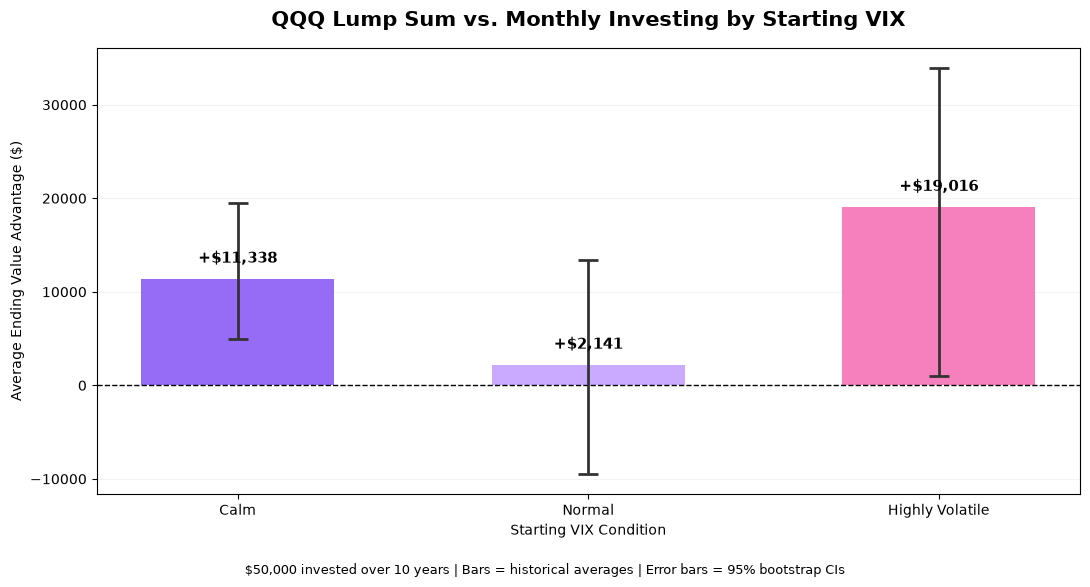

In [38]:
# Step 7: VIX comparison chart with 95% bootstrap intervals

order = ["Calm", "Normal", "Highly Volatile"]

# Use the bootstrap results calculated in Step 4.2
chart_data = (
    qqq_timing_bootstrap
    .set_index("VIX Condition")
    .loc[order]
)

means = chart_data["Average Difference"].to_numpy()
lower = chart_data["CI Lower"].to_numpy()
upper = chart_data["CI Upper"].to_numpy()

# Calculate asymmetric error bars
errors = np.vstack([
    means - lower,
    upper - means
])

fig, ax = plt.subplots(figsize=(11, 6))

colors = ["#8B5CF6", "#C4A1FF", "#F472B6"]

bars = ax.bar(
    order,
    means,
    color=colors,
    width=0.55,
    alpha=0.9,
    zorder=2
)

ax.errorbar(
    order,
    means,
    yerr=errors,
    fmt="none",
    ecolor="#333333",
    capsize=7,
    capthick=2,
    elinewidth=2,
    zorder=3
)

for bar, value in zip(bars, means):
    ax.annotate(
        f"+${value:,.0f}",
        xy=(bar.get_x() + bar.get_width() / 2, value),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

ax.axhline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_title(
    "QQQ Lump Sum vs. Monthly Investing by Starting VIX",
    fontsize=15,
    fontweight="bold",
    pad=16
)

ax.set_ylabel("Average Ending Value Advantage ($)")
ax.set_xlabel("Starting VIX Condition")

ax.grid(axis="y", alpha=0.15, zorder=0)

fig.text(
    0.5, 0.035,
    "$50,000 invested over 10 years | Bars = historical averages | Error bars = 95% bootstrap CIs",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.07, 1, 1])

# Save for your PowerPoint
plt.savefig(
    "vix_bootstrap_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [39]:
# Step 8: Sensitivity of BETWEEN-group comparisons

sensitivity_results = []

for block_size in [30, 60, 120]:

    result = bootstrap_vix_contrasts(
        comparison_table,
        difference_column="qqq_lump_vs_monthly",
        block_size=block_size,
        n_bootstrap=5000,
        seed=42
    )

    result["Block Size"] = block_size
    sensitivity_results.append(result)

contrast_sensitivity = pd.concat(
    sensitivity_results,
    ignore_index=True
)

print(
    contrast_sensitivity[
        [
            "Block Size",
            "Comparison",
            "Observed Difference",
            "CI Lower",
            "CI Upper"
        ]
    ].round(2).to_string(index=False)
)


 Block Size               Comparison  Observed Difference  CI Lower  CI Upper
         30   Highly Volatile - Calm              7678.25 -12596.58  24905.36
         30 Highly Volatile - Normal             16874.90  -1209.88  30970.09
         30            Calm - Normal              9196.65  -2343.01  23832.78
         60   Highly Volatile - Calm              7678.25 -12206.73  22753.79
         60 Highly Volatile - Normal             16874.90  -1215.64  32020.12
         60            Calm - Normal              9196.65    360.02  19413.98
        120   Highly Volatile - Calm              7678.25 -10105.86  22063.83
        120 Highly Volatile - Normal             16874.90   2323.82  29130.92
        120            Calm - Normal              9196.65   3728.91  15415.27


In [17]:
# Count wins and losses
lump_wins = (backtest_results["difference"] > 0).sum()
monthly_wins = (backtest_results["difference"] < 0).sum()
ties = (backtest_results["difference"] == 0).sum()

total = len(backtest_results)

# Calculate win rates
lump_win_rate = lump_wins / total * 100
monthly_win_rate = monthly_wins / total * 100

# Calculate average performance difference
avg_difference = backtest_results["difference"].mean()

print(f"Historical periods tested: {total}")
print(f"Lump Sum wins: {lump_wins} ({lump_win_rate:.2f}%)")
print(f"Monthly Investing wins: {monthly_wins} ({monthly_win_rate:.2f}%)")
print(f"Ties: {ties}")
print(f"Average difference: ${avg_difference:,.2f}")


Historical periods tested: 212
Lump Sum wins: 152 (71.70%)
Monthly Investing wins: 60 (28.30%)
Ties: 0
Average difference: $5,458.31


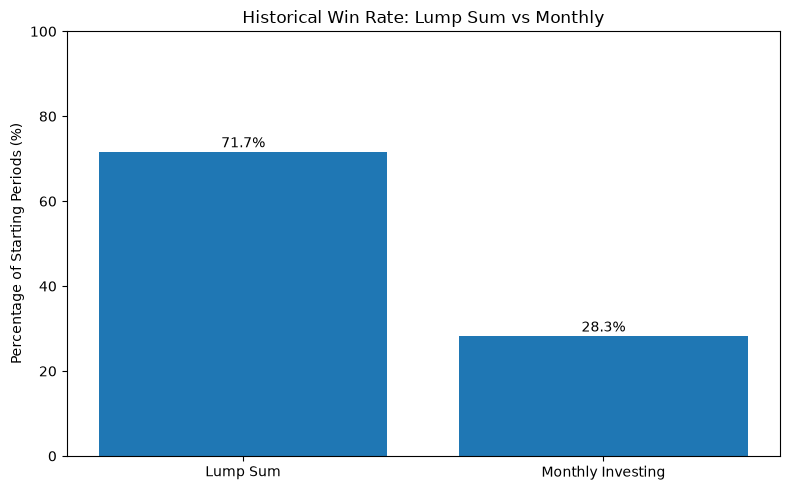

In [18]:
strategies = ["Lump Sum", "Monthly Investing"]
win_rates = [lump_win_rate, monthly_win_rate]

plt.figure(figsize=(8, 5))

bars = plt.bar(strategies, win_rates)

plt.title("Historical Win Rate: Lump Sum vs Monthly")
plt.ylabel("Percentage of Starting Periods (%)")
plt.ylim(0, 100)

for bar, rate in zip(bars, win_rates):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{rate:.1f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


In [19]:

# Ensure at least one historical period exists
assert not backtest_results.empty

# Check for missing values
assert not backtest_results.isna().any().any()

# Every period must produce nonnegative values
assert (backtest_results["lump_sum"] >= 0).all()
assert (backtest_results["monthly"] >= 0).all()

# Verify the difference calculation
assert np.allclose(
    backtest_results["difference"],
    backtest_results["lump_sum"] - backtest_results["monthly"]
)

# Verify we tested the expected number of windows
expected = len(complete_monthly_returns) - 120 + 1
assert len(backtest_results) == expected

print("Historical backtest checks passed!")


Historical backtest checks passed!


In [20]:
def block_bootstrap(
    differences,
    n_bootstrap=10000,
    block_size=120,
    seed=42
):
    rng = np.random.default_rng(seed)

    differences = np.asarray(differences, dtype=float)
    n = len(differences)

    if n == 0:
        raise ValueError("No historical differences provided")

    if not 1 <= block_size <= n:
        raise ValueError("Invalid block size")

    bootstrap_means = np.empty(n_bootstrap)

    for i in range(n_bootstrap):
        indices = []

        # Sample consecutive blocks of historical windows
        while len(indices) < n:
            start = rng.integers(0, n)

            block = (
                start + np.arange(block_size)
            ) % n

            indices.extend(block.tolist())

        # Keep the original sample length
        sample = differences[np.array(indices[:n])]

        bootstrap_means[i] = sample.mean()

    return bootstrap_means


In [21]:
# Get paired differences from the historical backtest
differences = backtest_results["difference"].to_numpy()

# Run block bootstrap
bootstrap_means = block_bootstrap(
    differences,
    n_bootstrap=10000,
    block_size=120
)

# Calculate 95% confidence interval
lower, upper = np.percentile(
    bootstrap_means,
    [2.5, 97.5]
)

# Actual historical average
mean_difference = differences.mean()

print(f"Historical average difference: ${mean_difference:,.2f}")

print(
    f"95% Bootstrap CI: "
    f"[${lower:,.2f}, ${upper:,.2f}]"
)


Historical average difference: $5,458.31
95% Bootstrap CI: [$490.42, $10,410.72]


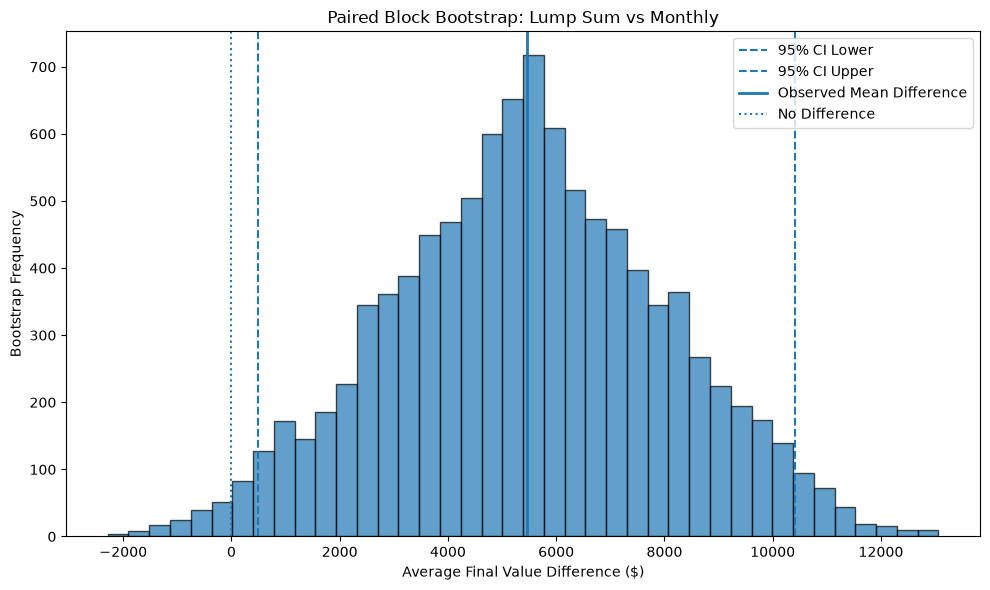

In [22]:
plt.figure(figsize=(10, 6))

plt.hist(
    bootstrap_means,
    bins=40,
    edgecolor="black",
    alpha=0.7
)

# Confidence interval
plt.axvline(
    lower,
    linestyle="--",
    label="95% CI Lower"
)

plt.axvline(
    upper,
    linestyle="--",
    label="95% CI Upper"
)

# Observed historical average
plt.axvline(
    mean_difference,
    linewidth=2,
    label="Observed Mean Difference"
)

# Zero = no average advantage
plt.axvline(
    0,
    linestyle=":",
    label="No Difference"
)

plt.title("Paired Block Bootstrap: Lump Sum vs Monthly")
plt.xlabel("Average Final Value Difference ($)")
plt.ylabel("Bootstrap Frequency")

plt.legend()
plt.tight_layout()
plt.show()


In [23]:
for block_size in [60, 120, 180]:
    samples = block_bootstrap(
        differences,
        n_bootstrap=10000,
        block_size=block_size,
        seed=42
    )

    ci = np.percentile(samples, [2.5, 97.5])

    print(
        f"Block size {block_size:3d}: "
        f"95% CI = [${ci[0]:,.2f}, ${ci[1]:,.2f}]"
    )


Block size  60: 95% CI = [$-10.41, $11,648.12]
Block size 120: 95% CI = [$490.42, $10,410.72]
Block size 180: 95% CI = [$2,232.74, $8,695.69]


In [24]:
# Monthly SPY prices
spy_monthly = prices["SPY"].resample("ME").last()

# Drawdown from previous historical peak
spy_drawdown = (
    spy_monthly / spy_monthly.cummax() - 1
)

def classify_market(drawdown):
    if drawdown <= -0.20:
        return "Crash"
    elif drawdown >= -0.05:
        return "Calm"
    else:
        return "Other"

# Label conditions known BEFORE each starting month
def get_market_condition(start_date):
    previous_month = start_date - pd.offsets.MonthEnd(1)
    drawdown = spy_drawdown.loc[previous_month]
    return classify_market(drawdown)

backtest_results["market_condition"] = (
    backtest_results["start_date"].apply(
        get_market_condition
    )
)

print(backtest_results["market_condition"].value_counts())


market_condition
Calm     84
Other    64
Crash    64
Name: count, dtype: int64


In [25]:
market_summary = (
    backtest_results
    .groupby("market_condition")
    .agg(
        periods=("difference", "count"),
        avg_difference=("difference", "mean"),
        lump_win_rate=(
            "difference",
            lambda x: (x > 0).mean() * 100
        )
    )
)

print(market_summary.round(2))


                  periods  avg_difference  lump_win_rate
market_condition                                        
Calm                   84         7145.88          73.81
Crash                  64        10061.03          78.12
Other                  64        -1359.34          62.50


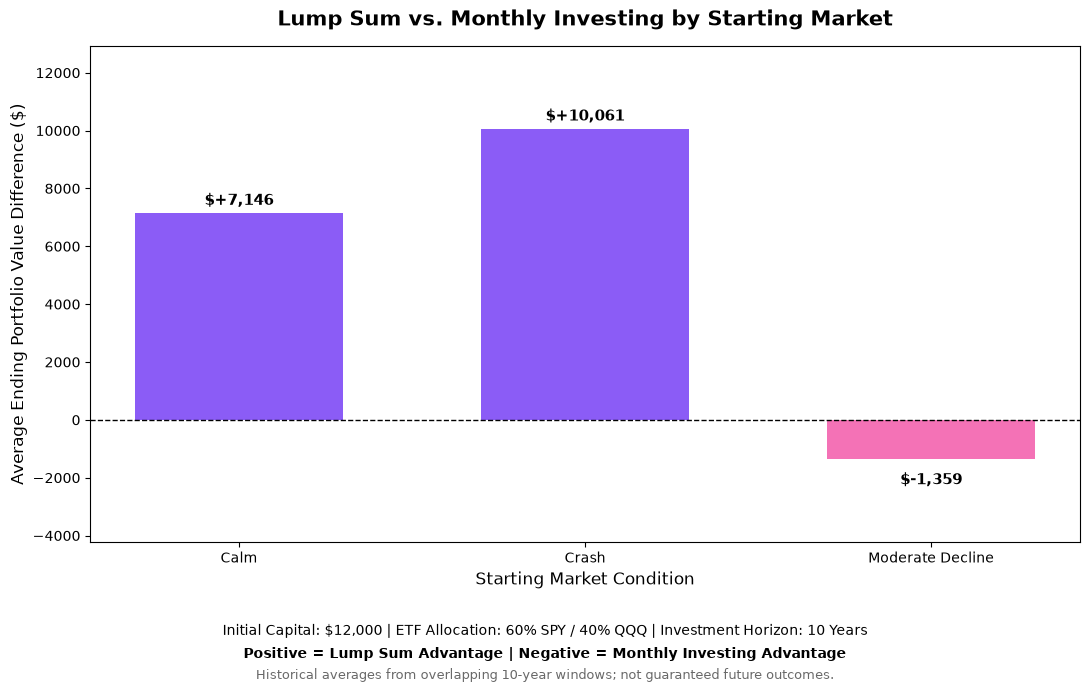

In [ ]:

# Put market conditions in a consistent order
order = ["Calm", "Crash", "Other"]
summary = market_summary.loc[order]
summary = summary.rename(index={"Other": "Moderate Decline"})

fig, ax = plt.subplots(figsize=(11, 7))

# Color based on which strategy performed better
colors = ["#8B5CF6" if value >= 0 else "#F472B6" for value in summary["avg_difference"]]

# Create bar chart
bars = ax.bar(
    summary.index,
    summary["avg_difference"],
    color=colors,
    width=0.6
)

# Add dollar labels to each bar
for bar, value in zip(bars, summary["avg_difference"]):
    ax.annotate(
        f"${value:+,.0f}",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            value
        ),
        xytext=(0, 6 if value >= 0 else -18),
        textcoords="offset points",
        ha="center",
        fontsize=11,
        fontweight="bold"
    )

# Zero line separates strategy advantages
ax.axhline(0, color="black", linestyle="--", linewidth=1)

# Chart title and labels
ax.set_title(
    "Lump Sum vs. Monthly Investing by Starting Market",
    fontsize=15,
    fontweight="bold",
    pad=15
)

ax.set_xlabel("Starting Market Condition", fontsize=12)
ax.set_ylabel(
    "Average Ending Portfolio Value Difference ($)",
    fontsize=12
)

# Add extra space around bars
ax.margins(y=0.25)

# Experiment assumptions
assumptions = (
    "Initial Capital: $50,000 | "
    "ETF Allocation: 60% SPY / 40% QQQ | "
    "Investment Horizon: 10 Years"
)

fig.text(
    0.5, 0.085,
    assumptions,
    ha="center",
    fontsize=10
)

# Explain positive vs negative values
fig.text(
    0.5, 0.052,
    "Positive = Lump Sum Advantage | "
    "Negative = Monthly Investing Advantage",
    ha="center",
    fontsize=10,
    fontweight="bold"
)

# Explain statistical limitations
fig.text(
    0.5, 0.022,
    "Historical averages from overlapping 10-year windows; "
    "not guaranteed future outcomes.",
    ha="center",
    fontsize=9,
    color="dimgray"
)

plt.tight_layout(rect=[0, 0.13, 1, 1])

plt.show()


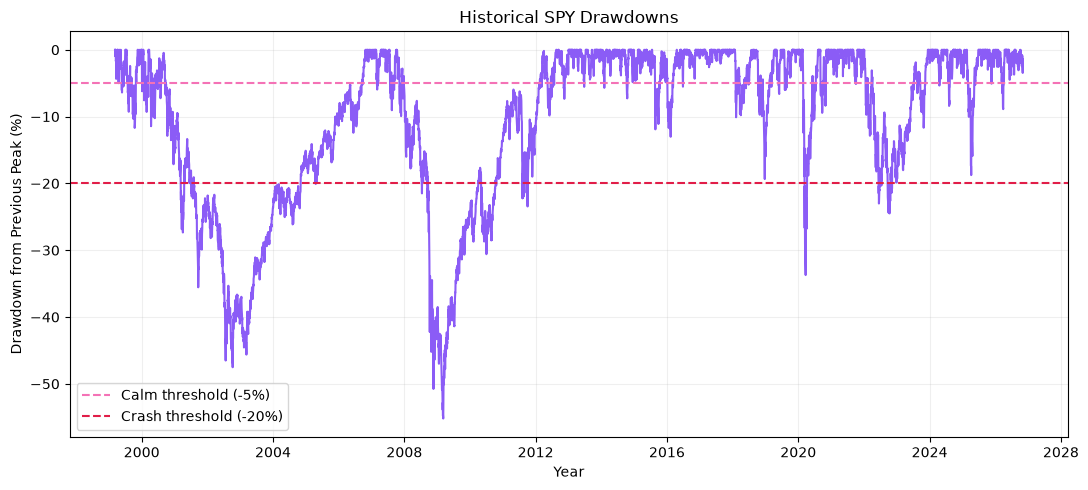

In [27]:
# Calculate SPY drawdown from its running peak
spy_prices = prices["SPY"]
spy_drawdown = spy_prices / spy_prices.cummax() - 1

plt.figure(figsize=(11, 5))

plt.plot(
    spy_drawdown.index,
    spy_drawdown * 100,
    color="#8B5CF6",
    linewidth=1.5
)

plt.axhline(
    -5,
    color="#F472B6",
    linestyle="--",
    label="Calm threshold (-5%)"
)

plt.axhline(
    -20,
    color="#E11D48",
    linestyle="--",
    label="Crash threshold (-20%)"
)

plt.title("Historical SPY Drawdowns")
plt.xlabel("Year")
plt.ylabel("Drawdown from Previous Peak (%)")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()